# Create manuscript figure 
Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2026-10-07.  
Copyright (c) 2026 - 2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

Figure 7 Cancer-associated biological programs are detectable in cfRNA.

uses file created by gsea.ipynb


In [1]:
defaultNotebookName="manuscriptGSEAPanel"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-11-22 10:43:02,550 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-11-22 10:43:02,551 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/graceM/src/python:/private/home/aedavids/graceM/src/jupyterNotebooks]
2026-11-22 10:43:02,552 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/graceM/src/python/cliUtilities.py]
2026-11-22 10:43:02,552 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/graceM/src/jupyterNotebooks]


In [2]:
import gseapy as gp
from IPython.display import display #, Image
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)

from pathlib import Path
import os
import pandas as pd
from typing import Any

#
# local imports
#
from notebookUtils import appendToPYTHONPATH, getNotebookName


ORIG_PYTHONPATH = os.environ['PYTHONPATH']

# extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
# extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
# appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2])

from data.loadCounts import loadDataFrame
from explainability.gseaUtilities import createBestGeneSetPlotData
from explainability.gseaUtilities import createEnsembleToHUGOMap

from plots.plotPanel import combineFiguresLayout, getSubplotWidthAndHeight, Panel
from plots.plotPanel import displayPDFInNotebook
from plots.plotPanel import setFigureFont


/private/home/aedavids/miniconda3/envs/graceM/lib/python3.13/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [3]:
from matplotlib import font_manager

availableFonts = sorted({
    font.name for font in font_manager.fontManager.ttflist
})

print(availableFonts)

['Abyssinica SIL', 'Ani', 'AnjaliOldLipi', 'Bitstream Vera Sans', 'Bitstream Vera Sans Mono', 'Bitstream Vera Serif', 'C059', 'Chandas', 'Chilanka', 'D050000L', 'DejaVu Math TeX Gyre', 'DejaVu Sans', 'DejaVu Sans Condensed', 'DejaVu Sans Display', 'DejaVu Sans Light', 'DejaVu Sans Mono', 'DejaVu Serif', 'DejaVu Serif Condensed', 'DejaVu Serif Display', 'Dhurjati', 'Droid Sans Fallback', 'Dyuthi', 'FontAwesome', 'FreeMono', 'FreeSans', 'FreeSerif', 'GLYPHICONS Halflings', 'Gargi', 'Garuda', 'Gayathri', 'Gayathri Thin', 'Gidugu', 'Gubbi', 'Gurajada', 'Inconsolata', 'Jamrul', 'KacstArt', 'KacstBook', 'KacstDecorative', 'KacstDigital', 'KacstFarsi', 'KacstLetter', 'KacstNaskh', 'KacstOffice', 'KacstOne', 'KacstPen', 'KacstPoster', 'KacstQurn', 'KacstScreen', 'KacstTitle', 'KacstTitleL', 'Kalapi', 'Kalimati', 'Karumbi', 'Keraleeyam', 'Khmer OS', 'Khmer OS System', 'Kinnari', 'LKLUG', 'LakkiReddy', 'Laksaman', 'Last Resort High-Efficiency', 'Lato', 'Lato Black', 'Lato Hairline', 'Lato Heavy'

In [4]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')

notebookOutDir = f'{notebookDir}/{notebookName}.out'
print(f'notebookOutDir: {notebookOutDir}')

imgOutDir = f'{notebookOutDir}/img'
os.makedirs(imgOutDir, exist_ok=True)
print(f'imgOutDir: {imgOutDir}')

imgPanelOutDir = f'{imgOutDir}/panel'
os.makedirs(imgPanelOutDir, exist_ok=True)
print(f'imgPanelOutDir: {imgPanelOutDir}')


notebookName: manuscriptGSEAPanel
notebookDir: /private/home/aedavids/graceM/src/jupyterNotebooks
notebookOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptGSEAPanel.out
imgOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptGSEAPanel.out/img
imgPanelOutDir: /private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptGSEAPanel.out/img/panel


In [5]:
# plot globals

BEST_N=1000

DIAGNOSIS = ["Colorectal Cancer", "Esophagus Cancer", "Healthy donor",
             "Lung Cancer", "Liver Cancer", "Stomach Cancer",]

GENE_SET_DB = [
    'MSigDB_Oncogenic_Signatures', # C6
    'Tabula_Sapiens', 
    'MSigDB_Hallmark_2020',
    'GO_Biological_Process_2026', 
    'KEGG_2026',
    'GTEx_Tissues_V8_2023',
    # 'ARCHS4_Cell-lines',
    'ARCHS4_Tissues',
    'clade',
    'family',
]


RANK_COL_NAME="NES"

signifignatTermsDir = f'{notebookDir}/gsea.out'


In [6]:
plotDataDict = createBestGeneSetPlotData(
                            signifignatTermsDir,
                            DIAGNOSIS,
                            GENE_SET_DB,
                            bestN=BEST_N,
                            rankColName=RANK_COL_NAME,
                            )

In [7]:
def gseaRemoveLegend( panel : plt.axes) -> None :
    ''' 
    copied from src/jupyterNotebooks/elifeVsTCGA/gseaPlots.ipynb
    
    the GSEAPY dotplot lengend displayes
    
    '% Genes in set' 
    
    all the genes are displayed as 100%. We should remove this ledgend
    Even if the coverage was displayed correclty it would confuse the readers
    of our paper. we only used genes that where expressed extracellular.
    we want to show that biologic programs are found in extracellular
    
    if you wanted to debug this start with
        ```
        print(df.columns)

        print(df[[
            "Gene %",
            "Gene %",
            "Gene_ratio",
            "Overlap"
        ]].head())
        ```
    '''
    legend = panel.get_legend()
    if legend is not None:
        legend.remove()


In [8]:
plotLayout_G: dict[str, Panel] = {
    # Cancer-type-associated MSigDB oncogenic signatures
    "a": Panel(
        "a", leftMm=0, topMm=0,
        widthMm=88, heightMm=85,
    ),

    # Pan-cancer MSigDB oncogenic signatures
    "b": Panel(
        "b", leftMm=92, topMm=0,
        widthMm=88, heightMm=85,
    ),

    # Pan-cancer KEGG pathways
    "c": Panel(
        "c", leftMm=0, topMm=90,
        widthMm=88, heightMm=75,
    ),

    # Single-sample ssGSEA comparison
    "d": Panel(
        "d", leftMm=92, topMm=90,
        widthMm=88, heightMm=75,
    ),
}

## <span style="color:red;background-color:yellow;">Figure F-R6-1 b)</span>

In [9]:
def configureDotplotColorbar(
    ax,
    colorLimits: tuple[float, float],
    ticks,
    fontSize: float = 7,
    tickFormat: str = ".1f",
    cmap: str = "viridis_r",
    ):
    """
    Set a fixed NES color mapping and matching colorbar labels.
    # The 2026-10-02 environment update upgraded GSEApy 1.2.1 -> 1.3.1
    # and Matplotlib 3.10.8 -> 3.11.2. Re-running the plotting code afterward
    # produced automatic limits of approximately [-1.84, -1.51], changing
    # the dot colors. The exact library change responsible is unconfirmed.
    # Explicit limits restore the manuscript's NES-to-color mapping without
    # modifying the underlying NES values.
    """
    vmin, vmax = sorted(colorLimits)

    if vmin == vmax:
        raise ValueError("Color limits must be different.")

    if any(tick < vmin or tick > vmax for tick in ticks):
        raise ValueError("All ticks must fall within the color limits.")

    for collection in ax.collections:
        colorbar = getattr(collection, "colorbar", None)
        if colorbar is None:
            continue

        collection.set_cmap(cmap)
        collection.set_norm(Normalize(vmin=vmin, vmax=vmax))
        colorbar.update_normal(collection)

        colorbar.set_ticks(ticks)
        colorbar.set_ticklabels([
            format(value, tickFormat) for value in ticks
        ])
        colorbar.ax.set_ylim(vmin, vmax)
        colorbar.ax.tick_params(labelsize=fontSize)

        colorbar.ax.set_title(
            colorbar.ax.get_title(loc="left"),
            loc="left",
            fontsize=fontSize,
        )

In [10]:
def plotFinalArtworkDotPlot(
            df : pd.DataFrame, 
            widthInMM : int,
            heightInMM : int,
            colorLimits: tuple[float, float],
            ticks : list[float],
            fontSize : int = 7,
            rankColName : str = "NES",
            markerSize : float = 1.5,
            tickFormat: str = ".1f",
            title : str = None,
            **dotplotOptions : Any,
    ) -> tuple[plt.figure, plt.axes]:
    ''' 
    TODO
    
    ref :
        https://gseapy.readthedocs.io/en/latest/run.html#gseapy.plot.dotplot
    '''
         
    cancerDF = df.loc[df["diagnosis"] != "Healthy" ].copy()
    
    figSize = (widthInMM / 25.4, heightInMM / 25.4)
    # fig, ax = plt.subplots(figsize=figSize)
    
    # create gp.dotplot argument dictionary
    optionsDict = {
        # column name in df that map the dot colors. Default: Adjusted P-value.
        "column": rankColName,
        
        # X, Categorical variable in df that map the x-axis data. Default: None.
        "x": "diagnosis",
        
        # y Categorical variable in df that map the y-axis data. Default: Term.
        "y": "Term",
        
        "size": markerSize,
        "xticklabels_rot": 45,
        "figsize": figSize,
    }
    # Add caller-supplied options, overriding defaults if provided.
    optionsDict.update(dotplotOptions)

    
    ax = gp.dotplot(
                cancerDF,
                # ** expands the items of the dictionary
                **optionsDict
            )
   
    configureDotplotColorbar(
                            ax=ax,
                            colorLimits=colorLimits, #(-3, -1),
                            ticks=ticks, #[-3, -2, -1],
                            tickFormat=tickFormat,
                            )
    
    ax.set_title( title) 


    # leaves the NES legend
    gseaRemoveLegend(ax)
    
    # set the font size
    # Class names, axis labels, and title.
    ax.tick_params(axis="both", labelsize=fontSize)
    ax.xaxis.label.set_fontsize(fontSize)
    ax.yaxis.label.set_fontsize(fontSize)
    ax.title.set_fontsize(fontSize)
    
    # change diagnosis -> Diagnosis
    ax.set_xlabel("Diagnosis")
    
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(fontSize) 
        legend.get_title().set_fontsize(fontSize)  
        
    # the rankColName is scale colorbar with it's own axes
    for collection in ax.collections:
        colorbar = getattr(collection, "colorbar", None)
        if colorbar is None:
            continue

        # Numbers alongside the colorbar.
        colorbar.ax.tick_params(axis="both", labelsize=fontSize)

        # GSEApy uses a left-aligned title for "NES".
        colorbar.ax.set_title(
            colorbar.ax.get_title(loc="left"),
            loc="left",
            fontsize=fontSize,
        )

    
    # 10/8/26 7pm 
    # fig = ax.figure
    #return (fig, ax)
    
    fig = ax.figure

    # Align rotated diagnosis labels.
    for text in ax.get_xticklabels():
        text.set_rotation(45)
        text.set_ha("right")
        text.set_rotation_mode("anchor")

    # make sure we use the correct fonts
    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)   

    # Fit labels and colorbar inside the fixed-size canvas.
    fig.tight_layout(pad=0.5)
    
 

    return (fig, ax)

layout[c].widthMm : 88
layout[c].heightMm : 75


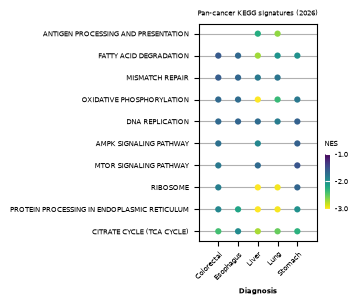

In [11]:
panelId = "c"
def Pan_cancerKEGG2026PathwaysFinalArtworkDotPlot () :
    ''' 
    based on intracBioFingerPrintsPanCancerSpecific() in
    src/jupyterNotebooks/elifeVsTCGA/cancerPathwaysAndSignal.ipynb
    '''
    plotData = plotDataDict['KEGG_2026']
    df = plotData.bestDownDF
    
    # print(df[["diagnosis", "Term", "NES"]].head(10))
    # print(pd.to_numeric(df["NES"]).describe())
    # print("*****")
    
    selectGeneSets = df.loc[:, 'Term'].isin([
                                        'DNA REPLICATION',
                                        'OXIDATIVE PHOSPHORYLATION',
                                        'RIBOSOME',
                                        'CITRATE CYCLE (TCA CYCLE)',
                                        'AMPK SIGNALING PATHWAY',
                                        'MTOR SIGNALING PATHWAY',
                                        
                                        # 7/14/26, add following from [15] intracBioFingerPrintsCancerTypeSpecific
                                        # for manuscript plots
                                        'PROTEIN PROCESSING IN ENDOPLASMIC RETICULUM',
                                        'MISMATCH REPAIR',
                                        'FATTY ACID DEGRADATION',  
                                        'ANTIGEN PROCESSING AND PRESENTATION',     
        ])
    
    df = df.loc[selectGeneSets, :]
    
    widthMM, heightMM = getSubplotWidthAndHeight(plotLayout_G, panelId )
    t = plotFinalArtworkDotPlot(
                                df=df, 
                                widthInMM=widthMM, #55,
                                heightInMM=heightMM, #55,
                                markerSize=0.75,
                                colorLimits=(-3, -1),
                                ticks=[-3, -2, -1],
                                #bestN=20,
                                # title=f"Pan Cancer Signatures\n{plotData.dbName}",
                                #title=f"Pan Cancer Signatures {plotData.dbName}",
                                title=f"Pan-cancer KEGG signatures (2026)",
                                fontSize=5, #6, 
                                )
    
    fig, ax = t
    return (fig, ax)

keggFig, keggAx = Pan_cancerKEGG2026PathwaysFinalArtworkDotPlot()
plotLayout_G[panelId].figure = keggFig

## <span style="color:red;background-color:yellow;">Figure F-R6-1 c) </span> 
Cancer-associated biological programs are detectable in cfRNA subplot (C) Cancer-type-specific MSigDB Oncogenic Signatures.

ref : src/jupyterNotebooks/elifeVsTCGA/gseaPlots.ipynb

In [12]:
def exploreMSigDB_OncogenicFinalArtwork() -> pd.DataFrame:
    """
    Select MSigDB oncogenic signatures for the cancer-type-associated
    final artwork panel.

    Source:
        MSigDB_Oncogenic_SignatureDownAxes()
        src/jupyterNotebooks/elifeVsTCGA/gseaPlots.ipynb

    Selection strategy:
        - Exclude Healthy.
        - Prefer signatures significant in fewer cancer diagnoses.
        - Prefer more negative NES within each diagnosis.
        - Manually select biologically relevant signatures.
        - Preserve all significant cancer observations for selected terms.

    Returns:
        DataFrame containing the selected programs for plotting.
    """

    geneCollectionName = "MSigDB_Oncogenic_Signatures"

    # ---------------------------------------------------------
    # 1. Prepare data
    # ---------------------------------------------------------

    plotDF = plotDataDict[geneCollectionName].bestDownDF

    cancerDF = plotDF.loc[
        plotDF["diagnosis"] != "Healthy"
    ].copy()

    # Number of cancer diagnoses in which each program
    # passed the significance filter.
    programCounts = (
        cancerDF.groupby("Term")["diagnosis"]
        .nunique()
    )

    cancerDF["nCancers"] = cancerDF["Term"].map(programCounts)

    # ---------------------------------------------------------
    # 2. Examine candidate programs
    # ---------------------------------------------------------

    # Programs significant in only one cancer diagnosis
    uniqueDF = cancerDF.loc[
        cancerDF["nCancers"] == 1
    ].copy()

    print("\nUnique programs per cancer:")
    print(
        uniqueDF.groupby("diagnosis")["Term"]
        .nunique()
        .sort_index()
    )

    print("\nUnique programs ranked by NES:")
    print(
        uniqueDF[
            ["diagnosis", "Term", "NES", "FDR q-val"]
        ]
        .sort_values(["diagnosis", "NES"])
        .to_string(index=False)
    )

    # Colorectal has no uniquely significant programs.
    # Rank its candidates by number of cancers first,
    # then by strongest negative NES.
    colorectalDF = cancerDF.loc[
        cancerDF["diagnosis"] == "Colorectal"
    ].sort_values(
        ["nCancers", "NES"],
        ascending=[True, True]
    )

    # ---------------------------------------------------------
    # 3. Manually selected programs
    # ---------------------------------------------------------

    selectedPrograms = [
        # Esophagus
        "E2F1 UP.V1 UP",
        "KRAS.DF.V1 DN",

        # Liver
        "RB P130 DN.V1 DN",
        "BMI1 DN.V1 DN",

        # Lung
        "ESC V6.5 UP LATE.V1 DN",
        "YAP1 DN",

        # Stomach
        "WNT UP.V1 UP",
        "BCAT GDS748 DN",

        # Colorectal
        # Add two programs after reviewing candidates.
        'TBK1.DN.48HRS DN',
        'PRC2 EDD UP.V1 UP'
    ]

    # Display colorectal candidates not already selected
    colorectalCandidates = colorectalDF.loc[
        ~colorectalDF["Term"].isin(selectedPrograms),
        ["Term", "nCancers", "NES", "FDR q-val"]
    ]

    print("\nColorectal candidates:")
    print(colorectalCandidates.to_string(index=False))

    # ---------------------------------------------------------
    # 4. Construct final plotting DataFrame
    # ---------------------------------------------------------

    selectedPlotDF = cancerDF.loc[
        cancerDF["Term"].isin(selectedPrograms)
    ].copy()

    # Check for misspelled or missing program names
    missingPrograms = (
        set(selectedPrograms) - set(selectedPlotDF["Term"])
    )

    if missingPrograms:
        raise ValueError(
            f"Selected programs not found: {sorted(missingPrograms)}"
        )

    print("\nFinal selection:")
    print("Programs:", selectedPlotDF["Term"].nunique())
    print("Significant observations:", len(selectedPlotDF))

    print(
        selectedPlotDF[
            ["diagnosis", "Term", "NES", "FDR q-val"]
        ]
        .sort_values(["diagnosis", "NES"])
        .to_string(index=False)
    )

    return selectedPlotDF



Unique programs per cancer:
diagnosis
Esophagus     3
Liver        14
Lung          2
Stomach       5
Name: Term, dtype: int64

Unique programs ranked by NES:
diagnosis                    Term       NES  FDR q-val
Esophagus           E2F1 UP.V1 UP -1.815021   0.005117
Esophagus           KRAS.DF.V1 DN -1.563494   0.045336
Esophagus            IL2 UP.V1 UP -1.563264   0.043892
    Liver        RB P130 DN.V1 DN -2.431991   0.000000
    Liver           BMI1 DN.V1 DN -2.073888   0.000000
    Liver               NFE2L2.V2 -1.919656   0.000908
    Liver          MEL18 DN.V1 DN -1.863727   0.001671
    Liver       CSR LATE UP.V1 DN -1.851053   0.001687
    Liver            RAF UP.V1 UP -1.846655   0.001702
    Liver           LTE2 UP.V1 UP -1.820698   0.002615
    Liver          HOXA9 DN.V1 DN -1.682078   0.006766
    Liver GCNP SHH UP EARLY.V1 UP -1.646490   0.008287
    Liver           PIGF UP.V1 UP -1.644363   0.008227
    Liver           ATF2 UP.V1 DN -1.582622   0.014850
    Liver      

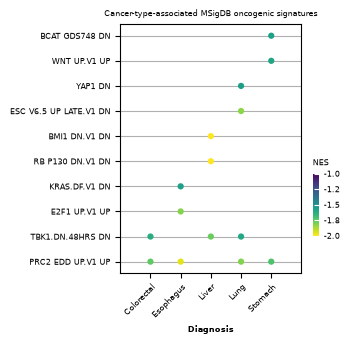

In [13]:
panelId = "a"
def MSigDB_OncogenicFinalArtwork() :
    df = exploreMSigDB_OncogenicFinalArtwork()
    
    #
    # plot code
    #
    bestN = 20
    # titleMSigDB_Oncogenic_SignatureDown = 'Cancer-type-specific MSigDB Oncogenic Signatures.'
    # titleMSigDB_Oncogenic_SignatureDown = 'Cancer-associated MSigDB oncogenic signatures'
    titleMSigDB_Oncogenic_SignatureDown = 'Cancer-type-associated MSigDB oncogenic signatures'
    #titleMSigDB_Oncogenic_SignatureDown="Pan-cancer enrichment\nMSigDB oncogenic signatures"
    widthMM, heightMM = getSubplotWidthAndHeight(plotLayout_G, panelId )

    t = plotFinalArtworkDotPlot(
                                # df=plotDF, 
                                df=df, 
                                widthInMM=widthMM, #50, #3 * 25.4,
                                heightInMM=heightMM, #75, #8 * 25.4,
                                markerSize=0.75,
                                colorLimits=(-2, -1),
                                ticks=[-2, -1.75, -1.5, -1.25, -1.0],
                                #    collection.set_clim(vmin=-2.0, vmax=-1.0)
                                #ticks = [-2.0, -1.75, -1.5, -1.25, -1.0],
                                #bestN=20,
                                title=titleMSigDB_Oncogenic_SignatureDown,
                                fontSize=6,
                                
                                # pass top_term to gp.dotplot()
                                top_term=bestN,
                                # tickFormat=".0f",
                                tickFormat=".1f",
                                )

    
    fig, ax = t
    return (fig, ax)

MSigDB_OncogenicFig, MSigDB_OncogenicAx = MSigDB_OncogenicFinalArtwork()
programLabels = [ tick.get_text() for tick in MSigDB_OncogenicAx.get_yticklabels() ]
print("Number of displayed programs:", len(programLabels))
print(programLabels)

plotLayout_G[panelId].figure = MSigDB_OncogenicFig

## <span style="color:red;background-color:yellow;">Figure F-R6-1 a) </span> 
Cancer-associated biological programs are detectable in cfRNA subplot (A) Pan-cancer MSigDB Oncogenic Signatures


layout[b].widthMm : 88
layout[b].heightMm : 85


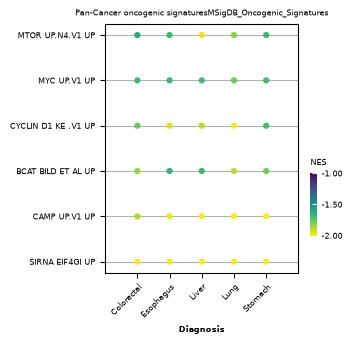

In [14]:
panelId = "b"
def PanCancerOncogenicSignaturesFinalArtwork() :
    ''' 
    based on PanCancerOncogenicSignatures() in 
    src/jupyterNotebooks/elifeVsTCGA/cancerPathwaysAndSignal.ipynb 
    '''
    plotData = plotDataDict['MSigDB_Oncogenic_Signatures']
    df = plotData.bestDownDF
    
    selectGeneSets = df.loc[:, 'Term'].isin([
                                            'MYC UP.V1 UP',
                                            'BCAT BILD ET AL UP',
                                            'MTOR UP.N4.V1 UP',
                                            'CYCLIN D1 KE .V1 UP',
                                            "SIRNA EIF4GI UP",
                                            "CAMP UP.V1 UP",
                                             ])
    
    df = df.loc[selectGeneSets, :]
    # title=f"Pan-Cancer Oncogenic Signatures\n{plotData.dbName}"
    # title=f"Pan-Cancer Oncogenic Signatures{plotData.dbName}"
    title=f"Pan-Cancer oncogenic signatures{plotData.dbName}"
    
    widthMM, heightMM = getSubplotWidthAndHeight(plotLayout_G, panelId )
    t = plotFinalArtworkDotPlot(
                                df=df, 
                                widthInMM=widthMM, #55,
                                heightInMM=heightMM, #55,
                                markerSize=0.75,
                                colorLimits=(-2, -1),
                                #ticks=[-3, -2, -1],
                                ticks=[-2, -1.5, -1.0],
                                title=title,
                                fontSize=6,
                                
                                # pass gp.dotplot optional argument
                                tickFormat=".2f",
                                )
    
    fig, ax = t
    return (fig, ax)
    
OncogenicFig, OncogenicAx = PanCancerOncogenicSignaturesFinalArtwork()
plotLayout_G[panelId].figure = OncogenicFig

## <span style="color:red;background-color:yellow;">F_R7_3  single sample GSEA</span>
ref:   
plotSampleProgramNES() in src/jupyterNotebooks/modelBiologyValidation/singleSampleBiologicInterpretation.ipynb 

In [15]:
def runSsGSEA(
        expressionDF: pd.DataFrame,
        geneSets: str | dict[str, list[str]],
        metaDF : pd.DataFrame
    ) -> pd.DataFrame:
    '''
    ssGSEA asks whether the genes belonging to that signature are concentrated toward 
    the highly expressed portion of that sample's ranked transcriptome.

    use all features even features with zero counts
    '''

    ssGSEAResult = gp.ssgsea(
        data=expressionDF,
        gene_sets=geneSets,
        sample_norm_method="rank",
        permutation_num=0,
        min_size=15,
        max_size=500,
        outdir=None,
        no_plot=True,
        threads=8,
    )

    return ssGSEAResult.res2d.sort_values(by="NES", ascending=False)

In [16]:
def loadElifeGTExTCGADataSet() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    ''' 
    TODO
    copied from src/jupyterNotebooks/elifeVsTCGA/analyzeIntraExtra.ipynb
    '''
    countDataDir = f'/private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out'
    
    elifeGTExTCGACountFile = f'{countDataDir}/elifeGTExTCGA_count.csv'
    elifeGTExTCGACountDF= loadDataFrame(elifeGTExTCGACountFile)
    elifeGTExTCGACountDF.set_index("geneId", inplace=True)
    print(f'countDataDir.shape : {elifeGTExTCGACountDF.shape}')
    display(elifeGTExTCGACountDF.iloc[0:5, 0:4])
    
    elifeGTExTCGAMetaFile = f'{countDataDir}/elifeGTExTCGA_metaData.csv'
    elifeGTExTCGAMetaDF= loadDataFrame(elifeGTExTCGAMetaFile)
    elifeGTExTCGAMetaDF.set_index('sample_id', inplace=True)
    print(f'elifeGTExTCGAMetaDF.shape : {elifeGTExTCGAMetaDF.shape}')
    display(elifeGTExTCGAMetaDF.head())
    
    elifeGTExTCGABiotypeFile = f'{countDataDir}/elifeGTExTCGA_bioTypes.csv'
    elifeGTExTCGABiotypeDF= loadDataFrame(elifeGTExTCGABiotypeFile)
    elifeGTExTCGABiotypeDF.set_index('geneId', inplace=True)
    print(f'elifeGTExTCGABiotypeDF.shape : {elifeGTExTCGABiotypeDF.shape}')
    display(elifeGTExTCGABiotypeDF.head())
    
    return (elifeGTExTCGACountDF, elifeGTExTCGAMetaDF, elifeGTExTCGABiotypeDF)
    
    
elifeGTExTCGACountDF, elifeGTExTCGAMetaDF, elifeGTExTCGABiotypeDF = loadElifeGTExTCGADataSet()

2026-11-22 10:43:07,314 WARNING loadCounts.py loadDataFrame() line:164] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_count.pandas.h5]


countDataDir.shape : (74352, 452)


/data/tmp/ipykernel_3212862/3763352643.py:10: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  elifeGTExTCGACountDF.set_index("geneId", inplace=True)


,COAD-3L-AA1B-TP,COAD-4T-AA8H-TP,COAD-5M-AAT6-TP,COAD-A6-5665-TP
geneId,,,,
(A)n,9,5,25,88
(AAA)n,0,0,0,0
(AAAAAAC)n,0,0,0,0
(AAAAAAG)n,0,0,0,0
(AAAAAAT)n,0,0,0,0


2026-11-22 10:43:07,775 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_metaData.csv]


elifeGTExTCGAMetaDF.shape : (446, 6)


... (2 outputs left out)

2026-11-22 10:43:07,785 WARNING loadCounts.py loadDataFrame() line:181] [loading : /private/groups/kimlab/data/elifeGTExTCGA/selectIntracellularSamples.out/elifeGTExTCGA_bioTypes.csv]


elifeGTExTCGABiotypeDF.shape : (74352, 1)


/data/tmp/ipykernel_3212862/3763352643.py:22: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  elifeGTExTCGABiotypeDF.set_index('geneId', inplace=True)


,bioType
geneId,
(A)n,repeatMask
(AAA)n,repeatMask
(AAAAAAC)n,repeatMask
(AAAAAAG)n,repeatMask
(AAAAAAT)n,repeatMask


In [17]:
def selectSamples(
        metaDF : pd.DataFrame,
        countDF : pd.DataFrame,
        dataSet : str,
    ) -> tuple[pd.DataFrame, pd.DataFrame]:
    ''' 
    TODO
    
    returns (samplesMetaDF,samplesCountDF ) 
    '''
    validDataSets = ['elife', 'GTEx', 'TCGA']
    if not dataSet in validDataSets :
        emsg = f'dataSet {dataSet} not in {validDataSets}'
        raise ValueError(emsg)
    
    selectRows=  metaDF['dataSet'] == dataSet
    samplesMetaDF = metaDF.loc[selectRows, :]
    print(f'samplesMetaDF.shape : {samplesMetaDF.shape}')   
    
    samplesCountDF = countDF.loc[:, samplesMetaDF.index]
    print(f'samplesCountDF.shape : {samplesCountDF.shape}')  
    
    return (samplesMetaDF, samplesCountDF) 
    
t = selectSamples(elifeGTExTCGAMetaDF, elifeGTExTCGACountDF, 'elife') 
elifeMetaDF, elifCountDF = t

samplesMetaDF.shape : (223, 6)
samplesCountDF.shape : (74352, 223)


In [18]:
dataOutDir = f'/scratch/aedavids/fagazi/singleSampleBiologicInterpretation.out'
os.makedirs(dataOutDir, exist_ok=True)


v39GeneMapPath= f'{dataOutDir}/v39GeneMap.csv'
v39GeneMapDF = createEnsembleToHUGOMap(mapFilePath=v39GeneMapPath)

print(f'v39GeneMapDF.shape : {v39GeneMapDF.shape}')
# smartDisplay(v39GeneMapDF.head(n=2))
# print()
# smartDisplay(v39GeneMapDF.tail(n=2))

2026-11-22 10:43:07,911 WARNING loadCounts.py loadDataFrame() line:164] [loading : /scratch/aedavids/fagazi/singleSampleBiologicInterpretation.out/v39GeneMap.pandas.h5]


v39GeneMapDF.shape : (77116, 7)


In [19]:
def mapENSG2HUGO(countDF : pd.DataFrame,
                 mapDF : pd.DataFrame,
                 ) :
    tmpCountDF = countDF.copy()
    tmpCountDF['originalIdx'] = tmpCountDF.index
    # print(*elifCountDF.columns)
    tmpCountDF['originalIdx'].head()
    countDFIndexName = countDF.index.name

    tmpMapDF = mapDF.loc[:, ['originalENSG', 'HUGO']].copy()
    mergedCountsDF = tmpCountDF.merge(
                        tmpMapDF,
                        left_on='originalIdx',
                        right_on='originalENSG',
                        how="outer",
                        indicator=True, # useful for debugging
                        suffixes=('_results', '_mapping'),
                    )
    
    print(f'mergedCountsDF.shape :{ mergedCountsDF.shape}')
    print(f'tmpCountDF.shape      : {tmpCountDF.shape}')
    selectBothOnlyRows = mergedCountsDF['_merge'] == "both"
    hugoDF = mergedCountsDF.loc[selectBothOnlyRows, :]
    
    # retHugoCountsDF = hugoDF.drop(columns="_merge")
    
    hugoDF.set_index("HUGO", inplace=True)
    hugoDF.index.name = countDFIndexName

    hugoDF = hugoDF.drop(columns=['_merge', 'originalIdx', 'originalENSG',])
        
    return hugoDF
    
    
hugoElifCountDF = mapENSG2HUGO(elifCountDF, v39GeneMapDF)


mergedCountsDF.shape :(77116, 227)
tmpCountDF.shape      : (74352, 224)


/data/tmp/ipykernel_3212862/1757747725.py:27: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  hugoDF.set_index("HUGO", inplace=True)


In [20]:
def plotSampleProgramNESFinalArtwork(
        resultDF: pd.DataFrame,
        sampleName: str,
        programName: str,
        widthInMM : int,
        heightInMM : int,
        fontSize : int,
    ) -> plt.figure :
    """
    Compare a single sample's ssGSEA NES with Healthy and diagnosis
    reference distributions for one oncogenic program.

    Parameters
    ----------
    resultDF : pd.DataFrame
        ssGSEA results containing:
        Name, Term, NES, and elifeDiagnosis.

    sampleName : str
        Sample identifier from the Name column.

    programName : str
        Oncogenic program from the Term column.

    Returns
    -------
    Figure
        Matplotlib figure.
    """

    programDF = resultDF[
        resultDF["Term"] == programName
    ].copy()

    sampleDF = programDF[
        programDF["Name"] == sampleName
    ]

    if sampleDF.empty:
        raise ValueError(
            f"Sample '{sampleName}' not found for program '{programName}'."
        )

    sampleNES = float(sampleDF["NES"].iloc[0])
    sampleDiagnosis = str(sampleDF["elifeDiagnosis"].iloc[0])

    healthyNES = (
        programDF.loc[
            programDF["elifeDiagnosis"] == "Healthy donor",
            "NES",
        ]
        .astype(float)
        .to_numpy()
    )

    diagnosisNES = (
        programDF.loc[
            programDF["elifeDiagnosis"] == sampleDiagnosis,
            "NES",
        ]
        .astype(float)
        .to_numpy()
    )

    if len(healthyNES) == 0:
        raise ValueError("No Healthy donor samples found.")

    if len(diagnosisNES) == 0:
        raise ValueError(
            f"No samples found for diagnosis '{sampleDiagnosis}'."
        )

    # Viridis colors
    viridis = plt.get_cmap("viridis")
    healthyColor = viridis(0.25)
    diagnosisColor = viridis(0.70)

    figSize = (widthInMM / 25.4, heightInMM / 25.4)
    fig, ax = plt.subplots(
                    figsize=figSize
    )

    # change 'Colorectal Cancer' to "Colorectal cancer"
    cleanSampleDiagnosis = sampleDiagnosis.replace("Cancer", 'cancer')

    boxplot = ax.boxplot(
        [healthyNES, diagnosisNES],
        vert=False,
        tick_labels=[
            "Healthy donor",
            # sampleDiagnosis,
            cleanSampleDiagnosis,
        ],
        patch_artist=True,
        widths=0.5,
        showfliers=True,
    )

    boxplot["boxes"][0].set_facecolor(healthyColor)
    boxplot["boxes"][1].set_facecolor(diagnosisColor)

    for box in boxplot["boxes"]:
        box.set_alpha(0.8)
    
    # Selected sample: keep the dashed line, without a legend.
    ax.axvline(
        sampleNES,
        linestyle="--",
        linewidth=2,
    )

    ax.set_xlabel("Single-sample GSEA NES")
    ax.set_title(programName)

    # Preserve the spacing shown in the PDF preview.
    ax.set_ylim(0.5, 2.8)

    # Set axis and title font sizes.
    ax.tick_params(axis="both", labelsize=fontSize)
    ax.xaxis.label.set_fontsize(fontSize)
    ax.yaxis.label.set_fontsize(fontSize)
    ax.title.set_fontsize(fontSize)

    # Apply the font family to all text, including the caption.
    fontFamily = natureManuscriptStyle["font.family"]
    setFigureFont(fig, fontFamily=fontFamily)

    # # Reserve approximately three text lines below the axes.
    # captionHeightInches = 3 * fontSize / 72
    # captionFraction = captionHeightInches / fig.get_figheight()

    # fig.tight_layout(rect=(0, captionFraction, 1, 1))
    fig.tight_layout()

    return fig    

    return fig

2026-11-22 10:43:08,546 [WARNING] Found duplicated gene names, values averaged by gene names!


layout[d].widthMm : 88
layout[d].heightMm : 75


/data/tmp/ipykernel_3212862/1395572556.py:86: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxplot = ax.boxplot(


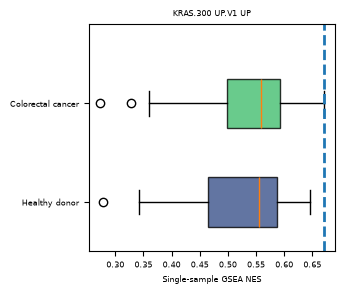

In [21]:
panelId = "d"
def colorectalKRASPlotSampleProgramNESFinalArtwork():
    ''' 
    plotSampleProgramNES() in src/jupyterNotebooks/modelBiologyValidation/singleSampleBiologicInterpretation.ipynb 
    '''
    
    resultsDF = runSsGSEA(
                    expressionDF=hugoElifCountDF,
                    geneSets="MSigDB_Oncogenic_Signatures",
                    metaDF=elifeMetaDF
                )
    # add diagnosis
    
    plotDataDF = resultsDF.copy().merge(
                                elifeMetaDF.loc[:, ['elifeDiagnosis']].copy(),
                                left_on='Name',
                                right_on='sample_id',
                                how="inner"
                                # how="outer",
                                # indicator=True, # useful for debugging
                                # suffixes=('_results', '_mapping'),
                            )

    widthMM, heightMM = getSubplotWidthAndHeight(plotLayout_G, panelId )
    colorectalKRASFig = plotSampleProgramNESFinalArtwork(
                            plotDataDF,
                            'SRR14506799',
                            'KRAS.300 UP.V1 UP',
                            widthInMM=widthMM, #100,
                            heightInMM=heightMM, #50,
                            # heightInMM=75,
                            fontSize=6,
                        )
    
    return (colorectalKRASFig, colorectalKRASFig.get_axes()[0])


sampleProgNESFig, sampleProgNESAx = colorectalKRASPlotSampleProgramNESFinalArtwork()
plotLayout_G[panelId].figure = sampleProgNESFig

In [22]:
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea


def plotGSEALegend(
        panelWidthInMM: float = 180,
        panelHeightInMM: float = 18,
        fontSize: float = 7,
    ) -> tuple[plt.Figure, plt.Axes]:
    """
    Create a centered text block with left-aligned lines.
    """
    fig, ax = plt.subplots(
        figsize=(
            panelWidthInMM / 25.4,
            panelHeightInMM / 25.4,
        )
    )
    ax.set_axis_off()

    bottomNote = (
        "a–c | Preranked GSEA: differentially expressed features detected "
        "in ≥10% of cfRNA samples,\n"
        "ranked by DESeq2 statistic. Shown: FDR ≤0.05 and |NES| ≥1.5.\n"
        "\n"
        "d | Dashed line: correctly classified colorectal sample. "
        #"Boxes: healthy donors and other colorectal samples."
    )

    textBlock = TextArea(
        bottomNote,
        textprops={
            "fontsize": fontSize,
            "multialignment": "left",
            "linespacing": 1.25,
            "color": "black",
        },
    )

    centeredText = AnchoredOffsetbox(
        loc="center",
        child=textBlock,
        bbox_to_anchor=(0.5, 0.5),
        bbox_transform=fig.transFigure,
        frameon=False,
        pad=0,
        borderpad=0,
    )

    ax.add_artist(centeredText)

    return fig, ax

## <span style="color:red;background-color:yellow;">create final artwork complient figure</span>

Layout valid: 180 × 165 mm total; panels occupy extents of 180 × 165 mm.


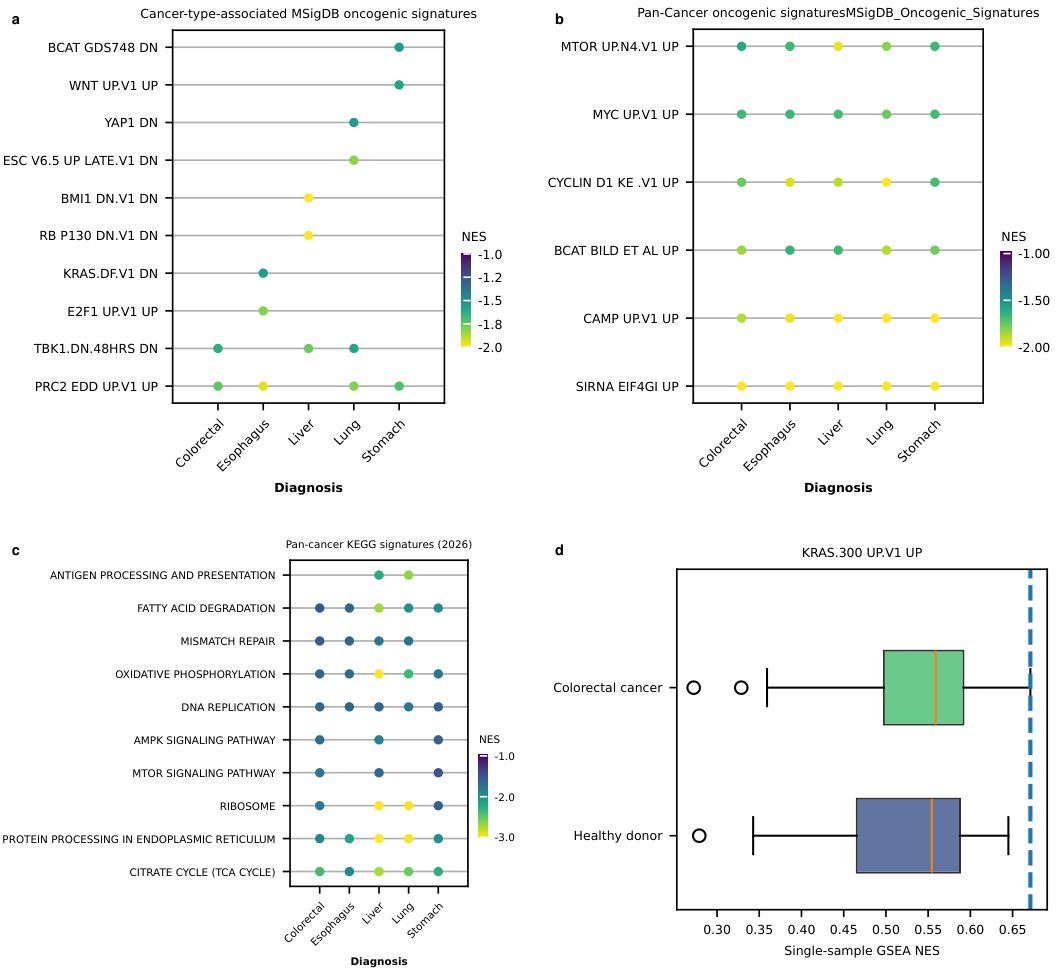

PosixPath('/private/home/aedavids/graceM/src/jupyterNotebooks/manuscriptGSEAPanel.out/img/panel/manuscript/F_R6_1_F_R7_3_gseaPanel.pdf')

In [23]:
F_R6_1_F_R7_3OutputStem = Path(f'{imgPanelOutDir}/manuscript/F_R6_1_F_R7_3_gseaPanel') 

panelWidthInMM = 180
legendHeightMM = 15
    
pdfPath, pngPath = combineFiguresLayout(
    panels=plotLayout_G,
    outputStem=F_R6_1_F_R7_3OutputStem,
    widthMm=panelWidthInMM, #180,
    heightMm=165, #150 + legendHeightMM, #145,
    legendHeightMm=0, #legendHeightMM,
    legendFigure=None, #legendFig,
)

displayPDFInNotebook( pdfPath )

pdfPath